# 01 · Explain a model with Kaimei

[Notebook 00](00-titanic-eda-and-models.ipynb) cleans the Kaggle Titanic data, engineers features and compares eight scikit-learn classifiers by accuracy. Accuracy says *how often* a model is right. It doesn't say *why* the model decides what it decides, or whether it's right for the right reasons.

This notebook takes the same features and gets those answers with [Kaimei](https://kaimei.ai):

1. train a random forest and a logistic regression, then upload both to Kaimei;
2. explain individual passengers, and find the smallest change that would flip the model's answer;
3. explain the same passenger with both models, and see why they disagree;
4. compare Kaimei's explanation methods;
5. analyse each model as a whole: global importance, learned rules, behaviour curves, interactions, robustness.

Everything here also appears on the Kaimei dashboard, where anyone on your team can explore it.

**Uses** 2 models, 6 explanations and 2 analyses of a free Kaimei plan, and takes about a minute.

**Before you start:** `pip install -r requirements.txt` from the repository root, and copy `.env.example` to `.env` with your Kaimei API key (dashboard → **API keys**). The notebook asks for the key if it can't find one.

> **Running on Google Colab or without a clone?** Install this example first; the data downloads by itself:
> ```python
> %pip install -q "titanic-kaimei-example[xgboost,serve] @ git+https://github.com/KaimeiAI/titanic-kaimei-example"
> ```

## 1. Connect

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

from kaimei.tabular import (
    compare_explanations,
    counterfactual_summary,
    explanation_summary,
    plot_counterfactual,
    plot_explanation,
    plot_insight,
)
from titanic_kaimei import FEATURES, OUTPUTS, encode, load, to_row
from titanic_kaimei.models import make_forest, make_logistic, scores
from titanic_kaimei.workspace import FOREST, LOGISTIC, connect, dashboard_url, ensure_project, replace_model, run_analysis

plt.rcParams["figure.dpi"] = 100
pd.set_option("display.precision", 3)

client = connect()  # reads KAIMEI_API_KEY from the environment or a .env file

Connected to Kaimei at https://api.kaimei.ai (workspace: Kaimei Workspace)


## 2. The data, kept human-readable

`load(1)` applies notebook 00's feature engineering ([`src/titanic_kaimei/data.py`](../src/titanic_kaimei/data.py)):
- missing ages get the median age and missing ports get Southampton;
- family size and travelling alone are derived from the sibling and parent counts;
- the title comes from the name, with rare titles grouped as `Other`.

One thing differs from notebook 00: categories stay as words. Models still need numbers, and `encode` provides them. Kaimei's feature schema (section 4) applies the same encoding, so every explanation reads `Sex = female` rather than `Sex = 0`. Age and fare stay in years and pounds for the same reason.

In [2]:
titanic = load(1)
passengers, survived = titanic.passengers, titanic.survived  # 891 passengers with known outcomes
passengers.head()

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,FamSize,IsAlone,Title
0,3,male,22.0,1,0,7.25,Southampton,2,False,Mr
1,1,female,38.0,1,0,71.28,Cherbourg,2,False,Mrs
2,3,female,26.0,0,0,7.92,Southampton,1,True,Miss
3,1,female,35.0,1,0,53.10,Southampton,2,False,Mrs
4,3,male,35.0,0,0,8.05,Southampton,1,True,Mr


## 3. Train two models

Kaimei runs these model families itself, so it can explain them with no scoring service of yours:
- scikit-learn linear models, trees, forests of up to 30 trees, MLPs and scaler pipelines;
- Keras / TensorFlow dense and convolutional networks;
- PyTorch modules.

Any other model (an SVC, XGBoost, a model behind your own API) works through a scoring endpoint or pre-computed attributions: see [notebook 04](04-bring-your-own-model.ipynb).

So the headline model here is a **30-tree random forest** rather than notebook 00's SVC; the table shows they score about the same. A **logistic regression** comes along for comparison.

In [3]:
X = encode(passengers)
forest, logistic = make_forest(), make_logistic()
svc = Pipeline([("scale", StandardScaler()), ("model", SVC())])  # notebook 00's pick, for reference only

scores({"Random forest": forest, "Logistic regression": logistic, "SVC (not uploaded)": svc}, X, survived)

,5-fold CV accuracy,validation accuracy
Random forest,0.827,0.827
Logistic regression,0.791,0.788
SVC (not uploaded),0.831,0.816


## 4. Upload both models

The **feature schema** tells Kaimei how to read a passenger:
- **`type`**: `numeric`, `integer`, `binary` or `categorical`.
- **`categories`**: for categorical features, the same lists the model was encoded with.
- **`unit`** and **`description`**: shown in the dashboard and in explanations.
- **`baseline`**: a typical passenger, which pre-fills the dashboard's Explain form.

It's defined once in [`src/titanic_kaimei/schema.py`](../src/titanic_kaimei/schema.py):

In [4]:
pd.DataFrame(FEATURES).astype(object).fillna("")

,name,type,min,max,baseline,description,categories,unit
0,Pclass,integer,1.0,3.0,3,"Ticket class: 1 = first, 2 = second, 3 = third",,
1,Sex,categorical,,,male,,"[female, male]",
2,Age,numeric,0.0,80.0,28,,,years
3,SibSp,integer,0.0,8.0,0,Siblings and spouses aboard,,
4,Parch,integer,0.0,6.0,0,Parents and children aboard,,
5,Fare,numeric,0.0,512.0,14.45,"Price of the whole ticket, shared by everyone ...",,GBP
6,Embarked,categorical,,,Southampton,Port of embarkation,"[Cherbourg, Queenstown, Southampton]",
7,FamSize,integer,1.0,11.0,1,"Family members aboard, including the passenger...",,
8,IsAlone,binary,,,True,Travelling without family,,
9,Title,categorical,,,Mr,Title from the passenger's name; rare titles a...,"[Dr, Master, Miss, Mr, Mrs, Other, Rev]",


`client.models.upload` reads the fitted estimator and uploads its structure: every split of every tree, or the scaler and coefficients. Kaimei stores that structure, not a pickle, and runs it itself. `X` and `y` attach reference passengers, which explanations and analyses compare against.

`replace_model` deletes an earlier upload with the same slug first, so this notebook can be run again.

In [5]:
project = ensure_project(client)
for slug, name, estimator, description in [
    (FOREST, "Titanic survival · random forest", forest,
     "30-tree random forest (max depth 5) on the Kaggle Titanic passenger list."),
    (LOGISTIC, "Titanic survival · logistic regression", logistic,
     "Standardized logistic regression on the same features, for comparison."),
]:
    replace_model(
        client, estimator, slug=slug, name=name, description=description, tags=["titanic", "example"],
        features=FEATURES, feature_names=list(X.columns), outputs=OUTPUTS,
        X=passengers, y=survived, project_id=project.id,
    )
    print(f"{name:42s} {dashboard_url('models/' + slug)}")
print(f"{'Project':42s} {dashboard_url('projects/' + project.slug)}")

Titanic survival · random forest           https://dashboard.kaimei.ai/models/titanic-forest


Titanic survival · logistic regression     https://dashboard.kaimei.ai/models/titanic-logistic
Project                                    https://dashboard.kaimei.ai/projects/titanic


Both models are on the dashboard now. On the forest's **Overview**, the architecture card walks a passenger down any of its 30 trees; the logistic regression shows its coefficients. The **Explain** tab is a form built from the schema above, with dropdowns for categories and a switch for `IsAlone`, pre-filled with the baselines.

## 5. Why did the model predict that?

Take the first passenger in the file, Mr Owen Harris Braund: 22 years old, third class, travelling with his brother. He died, and the forest agrees.

`client.explanations.create` asks Kaimei why. `method="shap"` computes SHAP values: each input's share of the gap between the model's average prediction and this one. For a model with ten inputs that Kaimei runs itself, it enumerates every coalition of features, so the numbers are exact for the reference sample. Other options:
- `counterfactual=True` also searches for the smallest change that would flip the decision;
- `frozen_features` keeps that search away from things a passenger couldn't change;
- `seed` fixes the reference sample, so these numbers repeat exactly from run to run.

The model predicts died: P(survived) = 7.4%, against 41.1% on average over the reference data. Pulling P(survived) down: Sex = male (−12.1 pts), Title = Mr (−11.0 pts), Pclass = 3 (−4.5 pts).


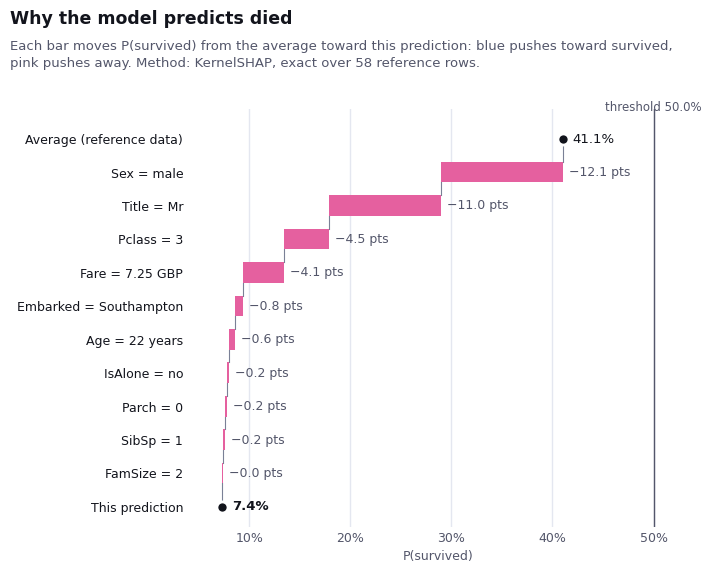

In [6]:
# Let the what-if search change only the ticket: class, fare and port.
EXPLAIN = {"counterfactual": True, "frozen_features": ["Sex", "Age", "Title", "SibSp", "Parch", "FamSize", "IsAlone"],
           "seed": 0}

braund = to_row(passengers.iloc[0])  # one passenger as plain JSON values, as your application would send it
explanation = client.explanations.create(model=FOREST, input=braund, method="shap", options=EXPLAIN)
forest_model = client.models.retrieve(FOREST)

print(explanation_summary(explanation, model=forest_model))
plot_explanation(explanation, model=forest_model)
plt.show()

Read the waterfall from the top. The first row is the forest's average answer over the reference passengers. Each bar below it is one input moving that number for this passenger, and the bars add up to his prediction. Being a man (`Sex`, and `Title = Mr`, which says the same thing) and travelling third class on a cheap ticket account for nearly all of the drop.

The same numbers as a table, which is what the explanation record stores:

In [7]:
pd.DataFrame(explanation.top_features)[["feature", "value", "attribution", "share"]]

,feature,value,attribution,share
0,Sex,male,-0.121,0.358
1,Title,Mr,-0.110,0.328
2,Pclass,3,-0.045,0.133
3,Fare,7.25,-0.041,0.120
4,Embarked,Southampton,-0.008,0.023
5,Age,22.0,-0.006,0.018
6,IsAlone,False,-0.002,0.007
7,Parch,0,-0.002,0.007


The second passenger in the file, Mrs Florence Cumings, travelled first class from Cherbourg. Same model, same question:

The model predicts survived: P(survived) = 97.5%, against 41.1% on average over the reference data. Pushing P(survived) up: Sex = female (+21.1 pts), Pclass = 1 (+13.0 pts), Fare = 71.28 GBP (+12.0 pts).


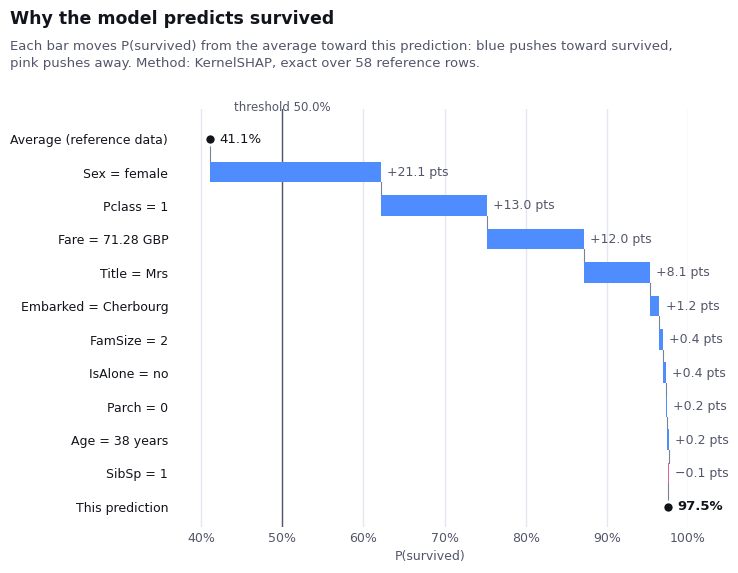

In [8]:
cumings = to_row(passengers.iloc[1])
explanation_cumings = client.explanations.create(model=FOREST, input=cumings, method="shap", options=EXPLAIN)
print(explanation_summary(explanation_cumings, model=forest_model))
plot_explanation(explanation_cumings, model=forest_model)
plt.show()

## 6. What would have had to change?

The counterfactual search changes one input at a time, at realistic values taken from the reference passengers. It stops as soon as the decision flips, or after three changes. Everything about the passenger is frozen (sex, age, title and family), so it can only change the ticket: class, fare and port. The question becomes *which ticket would have changed the model's answer?*

No change to at most 3 features flips the decision (Sex, Age, Title, SibSp, Parch, FamSize and IsAlone held fixed). The closest: Fare from 7.25 GBP to 57.81 GBP, which takes P(survived) 7.4% → 33.9%, still short of the 50.0% threshold.


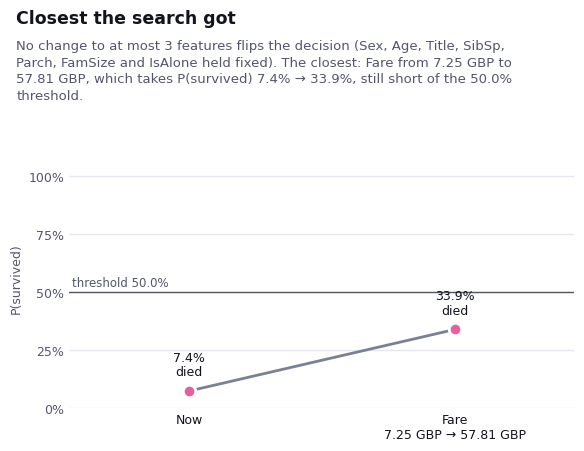

In [9]:
print(counterfactual_summary(explanation, model=forest_model))
plot_counterfactual(explanation, model=forest_model)
plt.show()

For Mr Braund, no ticket is enough. The search's best move is a first-class fare instead of his £7.25, which lifts him to roughly a one-in-three chance. Nothing it tries after that helps, and the forest still says *died*. For an adult man, the forest's answer barely depends on the ticket.

For Mrs Cumings, the same search shows how much of her survival the model credits to her ticket:

Changing Fare from 71.28 GBP to 8.421 GBP and Pclass from 1 to 3 flips the decision to died (Sex, Age, Title, SibSp, Parch, FamSize and IsAlone held fixed): P(survived) 97.5% → 43.1%.


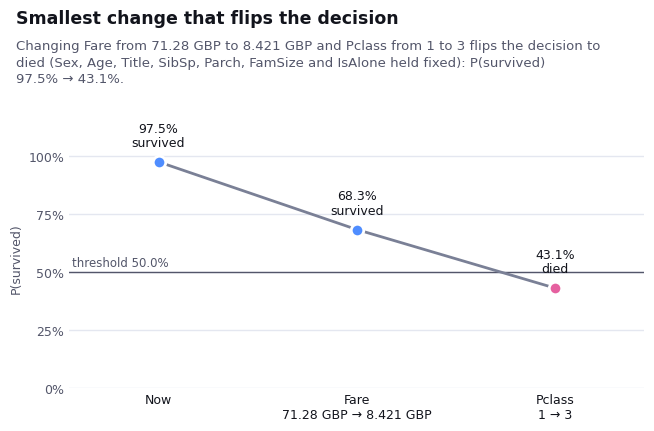

In [10]:
print(counterfactual_summary(explanation_cumings, model=forest_model))
plot_counterfactual(explanation_cumings, model=forest_model)
plt.show()

## 7. Same passenger, two models

The logistic regression scores a few points lower. Accuracy can't show where that difference comes from; explaining the same passenger with both models can.

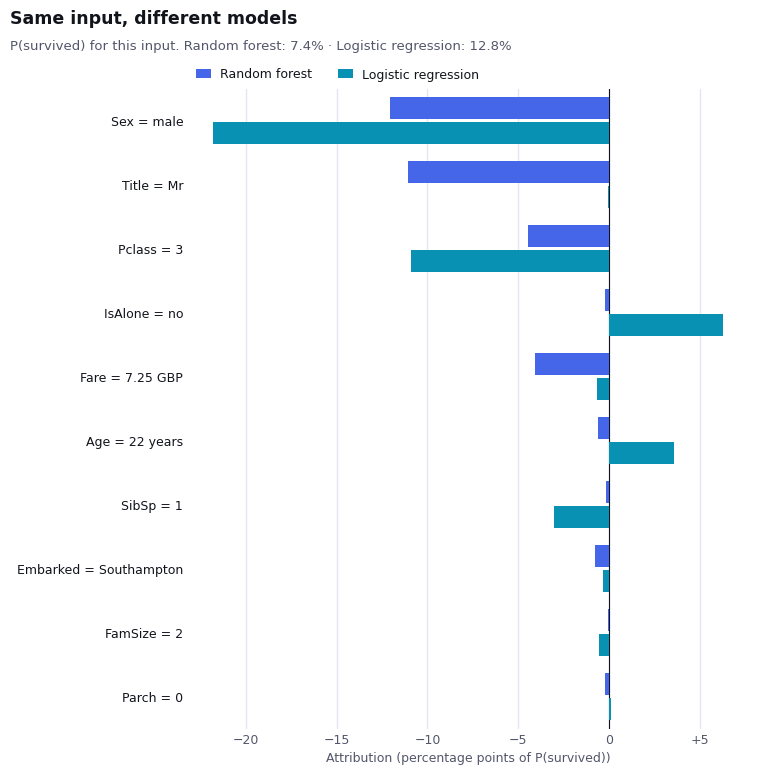

Forest:   No change to at most 3 features flips the decision (Sex, Age, Title, SibSp, Parch, FamSize and IsAlone held fixed). The closest: Fare from 7.25 GBP to 57.81 GBP, which takes P(survived) 7.4% → 33.9%, still short of the 50.0% threshold.
Logistic: Changing Pclass from 3 to 1 flips the decision to survived (Sex, Age, Title, SibSp, Parch, FamSize and IsAlone held fixed): P(survived) 12.8% → 54.1%.


In [11]:
logistic_model = client.models.retrieve(LOGISTIC)
explanation_logistic = client.explanations.create(model=LOGISTIC, input=braund, method="shap", options=EXPLAIN)

compare_explanations([explanation, explanation_logistic], ["Random forest", "Logistic regression"], model=forest_model)
plt.show()
print("Forest:  ", counterfactual_summary(explanation, model=forest_model))
print("Logistic:", counterfactual_summary(explanation_logistic, model=logistic_model))

Both models say he died, for different reasons:

- The **forest** splits the "adult man" signal between `Sex` and `Title = Mr`, and also counts his cheap fare against him.
- The **logistic regression** gets almost nothing out of `Title`. Titles are encoded by their alphabetical position (Dr, Master, Miss, Mr, Mrs, …), and a linear model can only weigh that order up or down, which means nothing for titles. So it leans on `Sex` and on class roughly twice as hard as the forest does.

That difference decides the what-if. For the logistic regression, a first-class ticket alone turns Mr Braund into a survivor; for the forest, no ticket does. Both models are around 80% accurate, yet they hold very different beliefs about what a ticket was worth. This is worth finding before a model goes live. It's also a concrete reason to one-hot encode titles if the linear model were the one to ship.

## 8. Choosing an explanation method

Kaimei offers three methods for tables, and they answer slightly different questions:

| Method | What it computes | When to use it |
| --- | --- | --- |
| `shap` (KernelSHAP) | Shapley values from a weighted regression over feature coalitions; exact when every coalition fits the budget, as here | the default: attributions add up exactly from the average to the prediction |
| `shapley` (permutation sampling) | Shapley values by walking random feature orders; reports a standard error per feature | very wide inputs (it screens hundreds of features) or when you want error bars |
| `lime` | a weighted linear model fitted around the passenger | a fast, local *slope*; it doesn't have to add up to the prediction |

On Mr Braund:

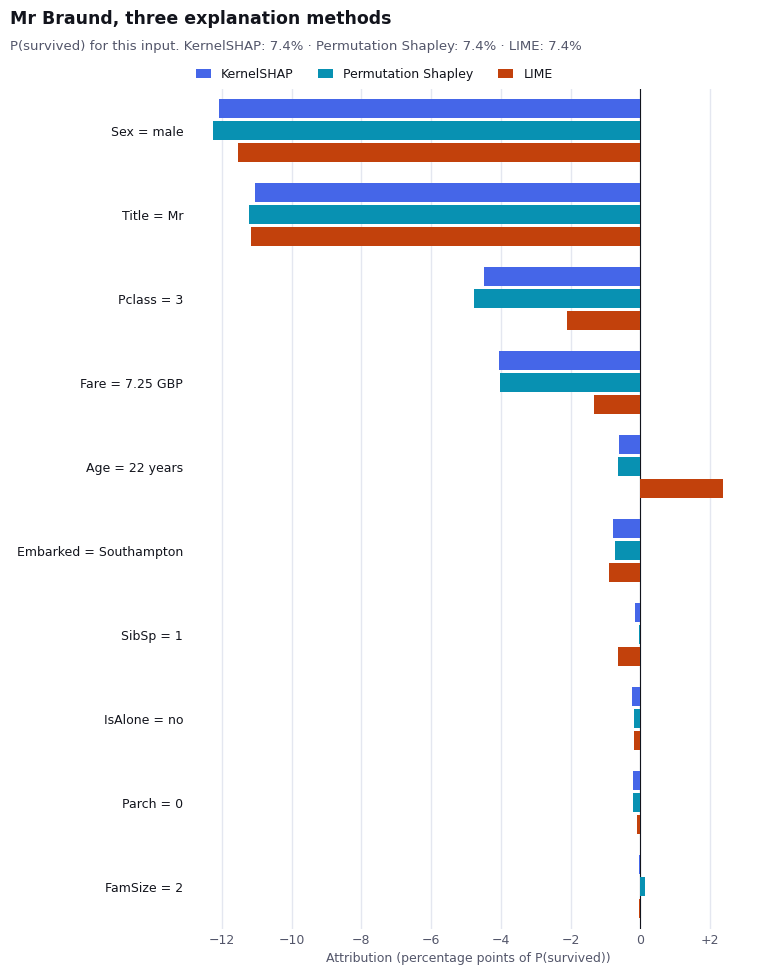

,method,model calls,server time (ms)
0,shap,59400,621.46
1,shapley,45633,622.83
2,lime,513,344.74


In [12]:
by_method = [
    client.explanations.create(model=FOREST, input=braund, method=method, options={"seed": 0, "log_prediction": False})
    for method in ["shap", "shapley", "lime"]
]
compare_explanations(by_method, ["KernelSHAP", "Permutation Shapley", "LIME"], model=forest_model,
                     title="Mr Braund, three explanation methods")
plt.show()
pd.DataFrame([{"method": e.method, "model calls": e.n_evals, "server time (ms)": e.latency_ms} for e in by_method])

The two Shapley methods agree to within sampling noise, as they should: they estimate the same quantity, one exactly and one by sampling. LIME agrees on what matters most (`Sex`, `Title`, class, fare) but reads `Age` the other way. Its straight-line fit around Mr Braund says being younger than average helps, while the Shapley methods follow the forest's actual, non-linear response and find his age slightly against him. When the two kinds of method disagree, trust the Shapley values for *how much each input moved this prediction*, and LIME for *which way a small change would push it*.

## 9. The model as a whole

A **full analysis** studies a model across its reference passengers and produces **insights**:
- global importance;
- behaviour curves;
- the rules it has learned;
- interactions;
- robustness to noisy inputs;
- the distribution of its predictions;
- drift, once production traffic is logged ([notebook 02](02-monitor-in-production.ipynb)).

In [13]:
insights = run_analysis(client, FOREST)
logistic_insights = run_analysis(client, LOGISTIC)
sorted(insights)

['behavior',
 'drift',
 'global_importance',
 'interactions',
 'learned_rules',
 'partial_dependence',
 'robustness']

**What matters overall.** Permutation importance shuffles one input at a time across the reference passengers and measures how much the forest's output moves. The learned rules below it put the strongest effects into sentences.

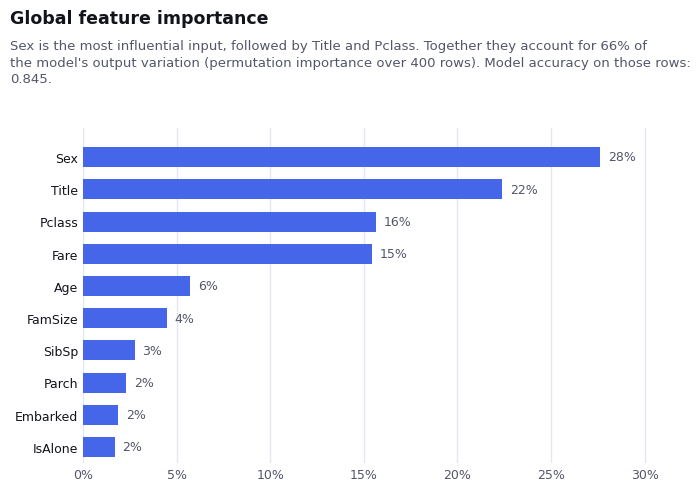

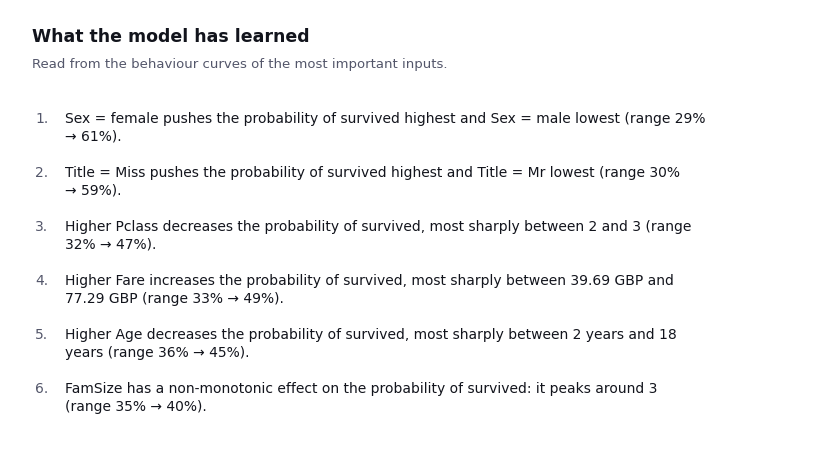

In [14]:
plot_insight(insights["global_importance"], model=forest_model)
plt.show()
plot_insight(insights["learned_rules"], model=forest_model)
plt.show()

Each rule names where its effect changes most, and read together they tell the familiar story: sex and title first, then class. Age matters mostly in childhood: the forest's average answer falls from about 45% for a 2-year-old to under 39% by 18, and changes little after that. "Women and children first" is in the data, and the forest learned it.

**How each input acts.** Each panel varies one input across its range for every reference passenger and averages the forest's answer (the blue line). The faint lines are individual passengers, and where they don't move in parallel, that input interacts with something else.

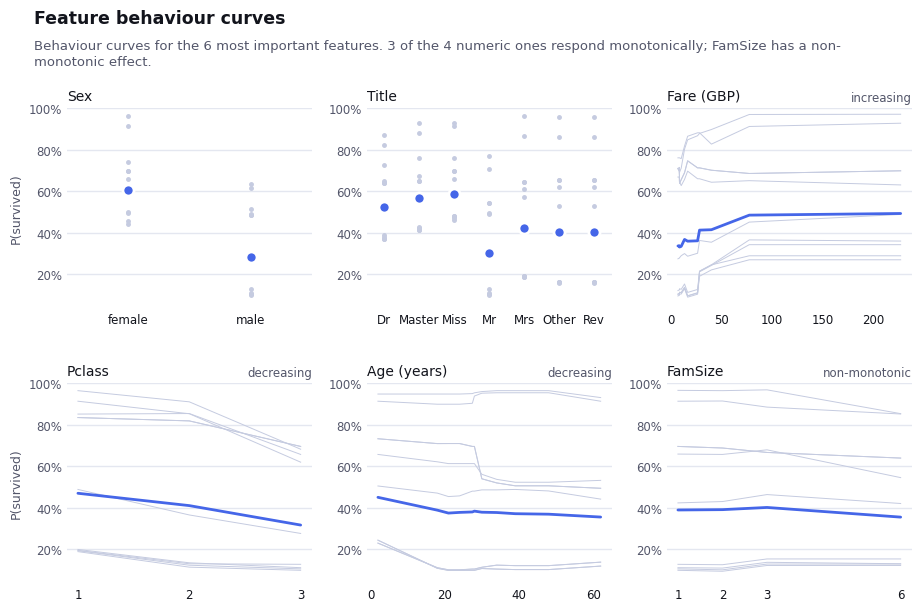

In [15]:
plot_insight(insights["partial_dependence"], model=forest_model)
plt.show()

**Interactions.** These are the pairs whose combined effect isn't the sum of their separate effects.

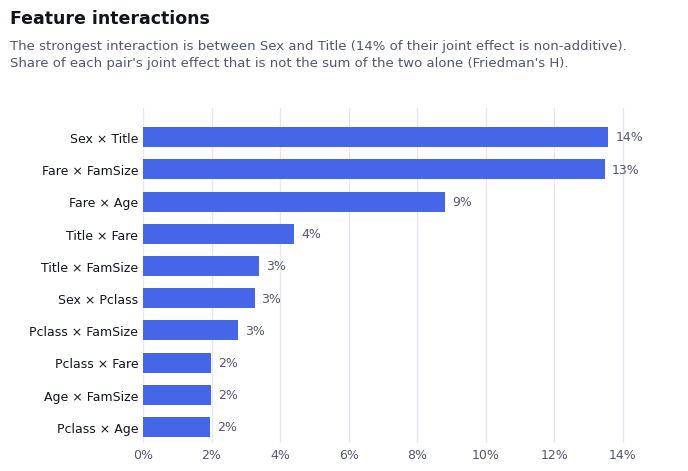

In [16]:
plot_insight(insights["interactions"], model=forest_model)
plt.show()

Two of the strongest pairs each say something about the data:

- **Sex × Title** is two encodings of one fact: `Mr` already means an adult man.
- **Fare × FamSize** is a quirk of the Kaggle file. `Fare` is the price of the whole ticket, shared by everyone travelling on it, so the same fare means something different for a family than for someone alone. A fare per person would be a better feature (notebook 03).

Kaimei surfaced both without being told what to look for.

**Behaviour and robustness.** Behaviour shows how confident the forest is across the population, and how many passengers sit near the 50% line. Robustness shows how often a decision flips when the inputs get a little noise.

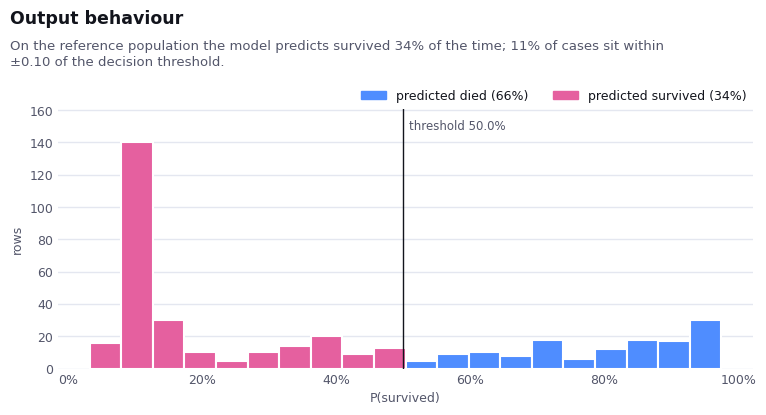

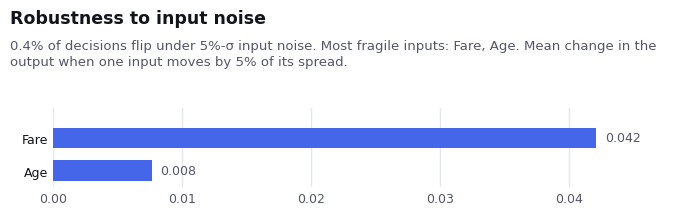

In [17]:
for kind in ["behavior", "robustness"]:
    plot_insight(insights[kind], model=forest_model)
    plt.show()

## 10. On the dashboard

Everything above is now in the **Titanic survival** project:

- **Projects → Titanic survival**: both models side by side, and a feature × model heatmap of what drives each. `Title` matters to the forest and barely registers for the logistic regression.
- **Models → random forest → Overview**: the architecture card. Pick any of the 30 trees and watch a passenger walk down it.
- **Explain**: the schema as a form. Change `Sex` or `Pclass` and explain again.
- **Insights**: the cards drawn above, with a *Run full analysis* button.
- **Explanations**: every explanation made from this notebook or from the dashboard.

**Next:** [02 · Monitor in production](02-monitor-in-production.ipynb) logs traffic for these models and catches a data-pipeline bug with drift detection.

In [18]:
for page in ["projects/titanic", f"models/{FOREST}", f"models/{FOREST}/explain", f"models/{LOGISTIC}"]:
    print(dashboard_url(page))

https://dashboard.kaimei.ai/projects/titanic
https://dashboard.kaimei.ai/models/titanic-forest
https://dashboard.kaimei.ai/models/titanic-forest/explain
https://dashboard.kaimei.ai/models/titanic-logistic
